Explore the data, visualize the churn, investigate patterns

Python, Pandas, scikit-learn, and Jupyter Notebook

In [1]:
#libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
# load csv into df
df = pd.read_csv('F:/Projects/customer-churn-prediction/data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.head())


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
columns = df.columns

## column of interest: 'Churn'- target variable
                #   ' customerID' - unique identifier for each customer
                #   ' SeniorCitizen' - binary variable indicating if the customer is a senior citizen
                #  ' tenure' - number of months the customer has been with the company'
                #   ' MonthlyCharges' - monthly charges for the customer
                #   ' TotalCharges' - total charges for the customer
                #  ' Contract' - type of contract the customer has (month-to-month, one year, two year)
                #  ' PaymentMethod' - method of payment for the customer (electronic check, mailed check, bank transfer, credit card)
                #  ' MultipleLines' - binary variable indicating if the customer has multiple lines
                #  ' PhoneService' - binary variable indicating if the customer has phone service
                #  ' InternetService' - type of internet service the customer has (DSL, fiber optic, none)
                #  ' Dependents' - binary variable indicating if the customer has dependents
                #  ' PaperlessBilling' - binary variable indicating if the customer has paperless billing

In [37]:
#change senior citizen to string
df['SeniorCitizen'] = df['SeniorCitizen'].replace({1: 'Yes', 0: 'No'}).astype(str)

In [38]:
TotalCharges = df['TotalCharges'].replace(" ", np.nan).astype(float)
print("Missing values in TotalCharges after conversion:\n", TotalCharges.isnull().sum())

Missing values in TotalCharges after conversion:
 0


Since the missing values in TotalCharges column are due to the fact that they have a tenure of 0 months (new customers, haven't been billed yet), which wouldn't be useful in this analysis --> these rows can be dropped

In [39]:
#drop rows with missing values in TotalCharges
df = df[df['TotalCharges'].notnull()]
print("Missing values after dropping rows with missing TotalCharges:\n", df.isnull().sum())

Missing values after dropping rows with missing TotalCharges:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [40]:
print("Data types after cleaning:\n", df.dtypes)

Data types after cleaning:
 customerID              str
gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure              float64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [41]:
# change TotalCharges to float
df[df['TotalCharges'] == " "] = np.nan
df['TotalCharges'] = df['TotalCharges'].astype(float)
print("Data types after converting TotalCharges to float:\n", df.dtypes)

Data types after converting TotalCharges to float:
 customerID              str
gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure              float64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [42]:
# check for missing values in all columns
missing_values = df.isnull().sum()
print("Missing values after cleaning:\n", missing_values)

Missing values after cleaning:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [44]:
print("Data types after cleaning:\n", df.dtypes)

Data types after cleaning:
 customerID              str
gender                  str
SeniorCitizen       float64
Partner                 str
Dependents              str
tenure              float64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


## now into looking at different variables

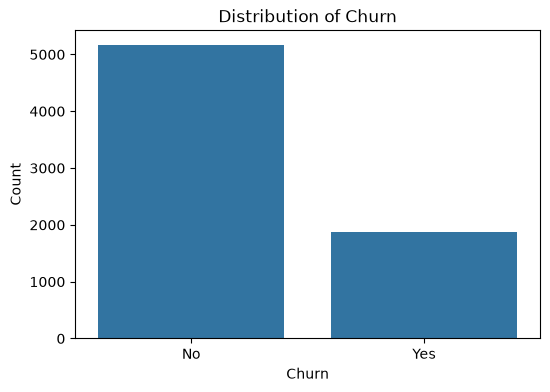

In [46]:
# let's check the distribution of the target variable 'Churn'
plt.figure(figsize=(6,4))
plot = sns.countplot(x='Churn', data=df)
plot.set_title('Distribution of Churn')
plot.set_xlabel('Churn')
plot.set_ylabel('Count')
plt.show()

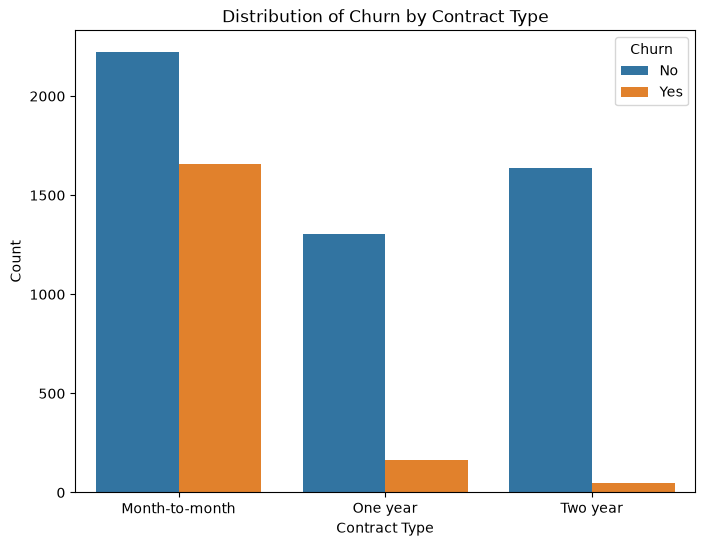

In [47]:
# now let's check the distribution of the target variable 'Churn' with respect to the 'Contract' type
plt.figure(figsize=(8,6))
plot = sns.countplot(x='Contract', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Contract Type')
plot.set_xlabel('Contract Type')
plot.set_ylabel('Count')
plt.show()

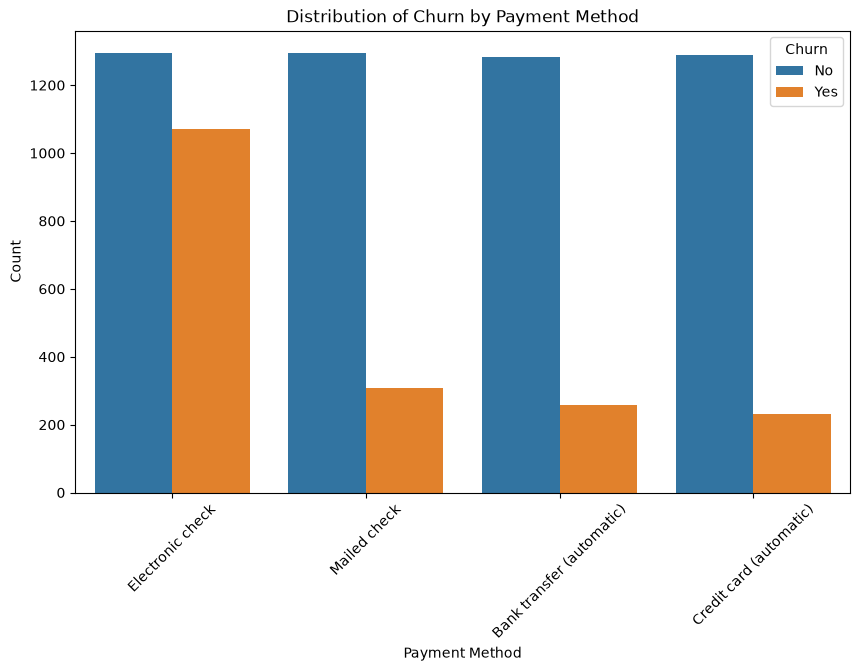

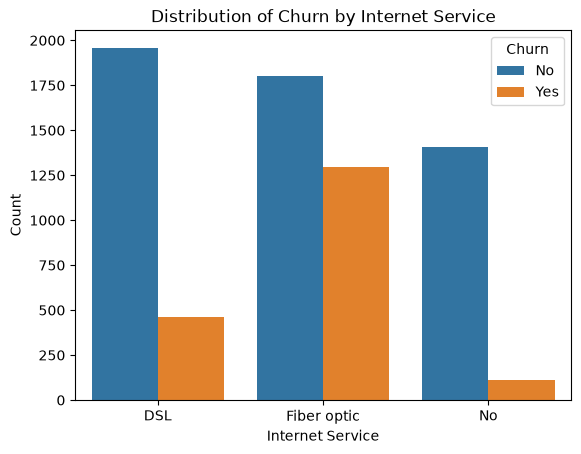

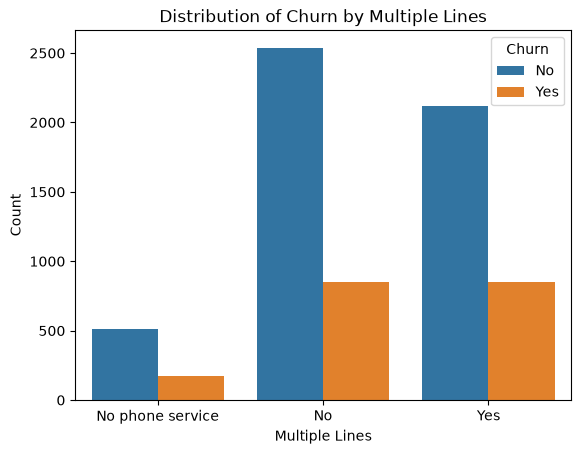

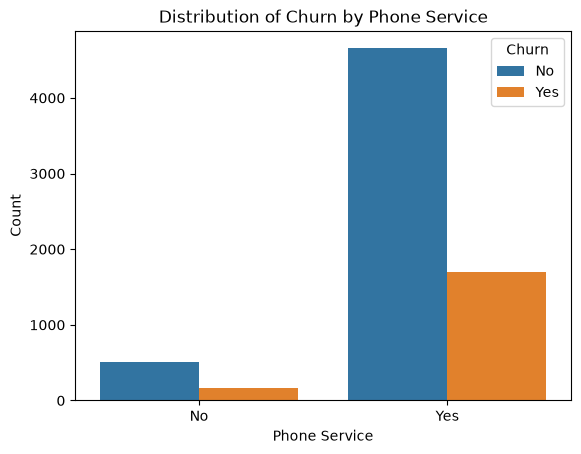

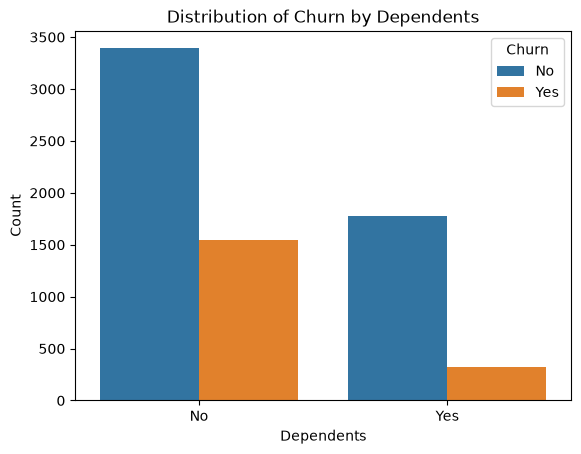

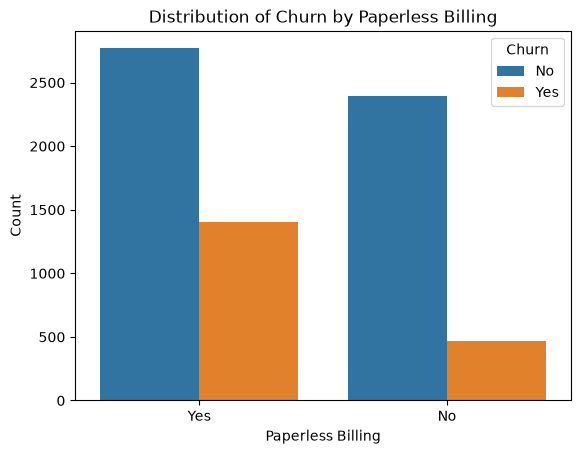

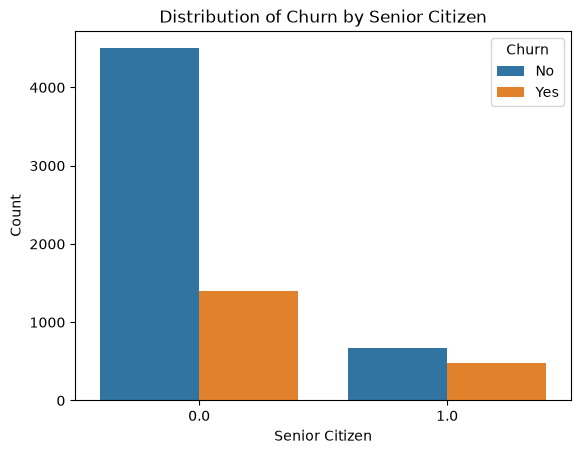

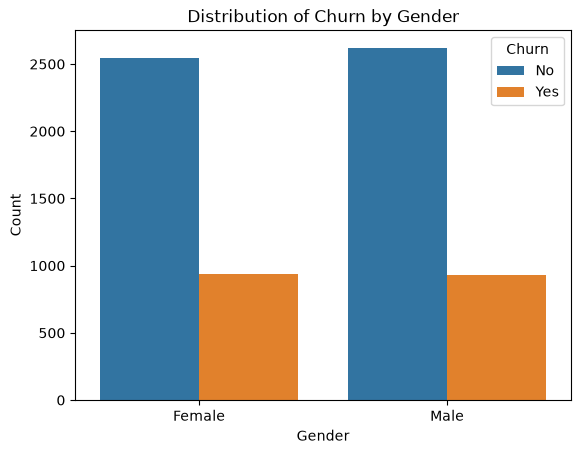

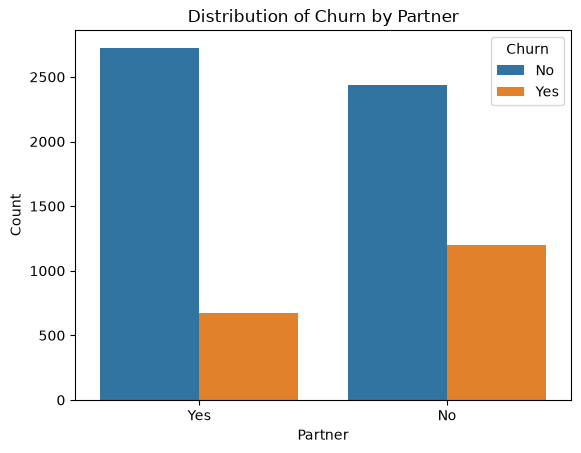

In [50]:
# now let's check the distribution of the target variable 'Churn' with respect to 'the 'PaymentMethod' type
plt.figure(figsize=(10,6))
plot = sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Payment Method')
plot.set_xlabel('Payment Method')
plot.set_ylabel('Count')
plt.xticks(rotation=45)
plt.show()
plot = sns.countplot(x='InternetService', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Internet Service')
plot.set_xlabel('Internet Service')
plot.set_ylabel('Count')
plt.show()  
plot = sns.countplot(x='MultipleLines', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Multiple Lines')
plot.set_xlabel('Multiple Lines')
plot.set_ylabel('Count')
plt.show()
plot = sns.countplot(x='PhoneService', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Phone Service')
plot.set_xlabel('Phone Service')
plot.set_ylabel('Count')
plt.show()
plot = sns.countplot(x='Dependents', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Dependents')
plot.set_xlabel('Dependents')
plot.set_ylabel('Count')
plt.show()
plot = sns.countplot(x='PaperlessBilling', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Paperless Billing')
plot.set_xlabel('Paperless Billing')
plot.set_ylabel('Count')
plt.show()
plot = sns.countplot(x='SeniorCitizen', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Senior Citizen')
plot.set_xlabel('Senior Citizen')
plot.set_ylabel('Count')
plt.show()
plot = sns.countplot(x='gender', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Gender')
plot.set_xlabel('Gender')
plot.set_ylabel('Count')
plt.show()
plot = sns.countplot(x='Partner', hue='Churn', data=df)
plot.set_title('Distribution of Churn by Partner')
plot.set_xlabel('Partner')
plot.set_ylabel('Count')
plt.show()


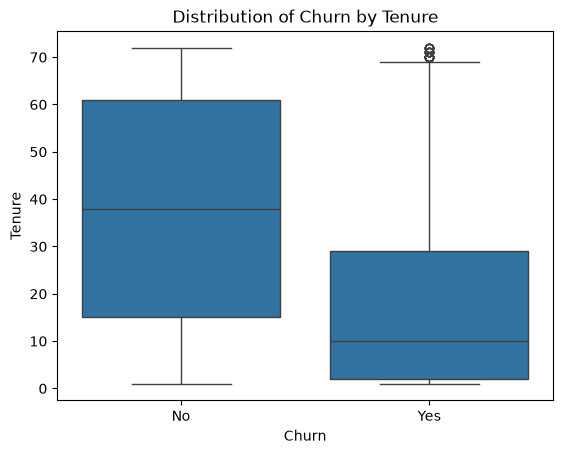

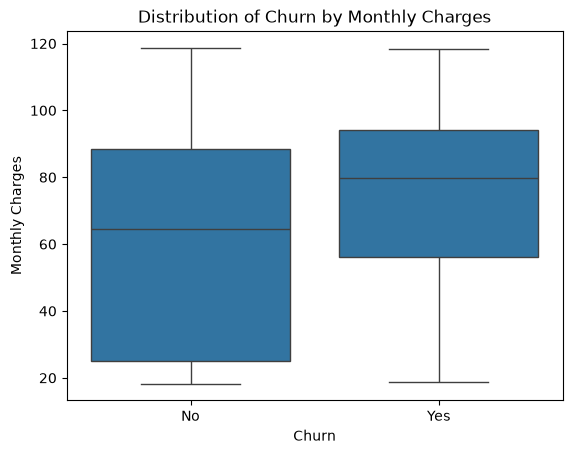

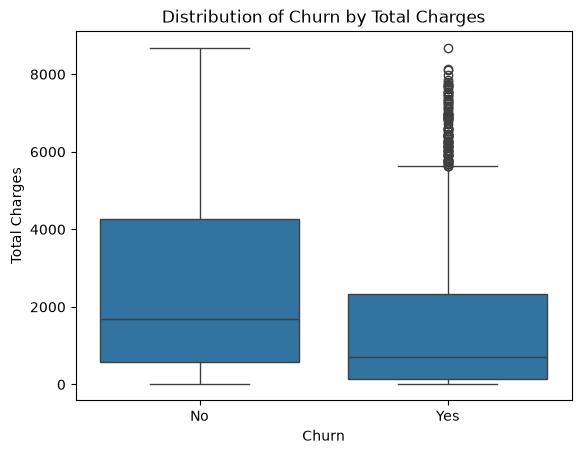

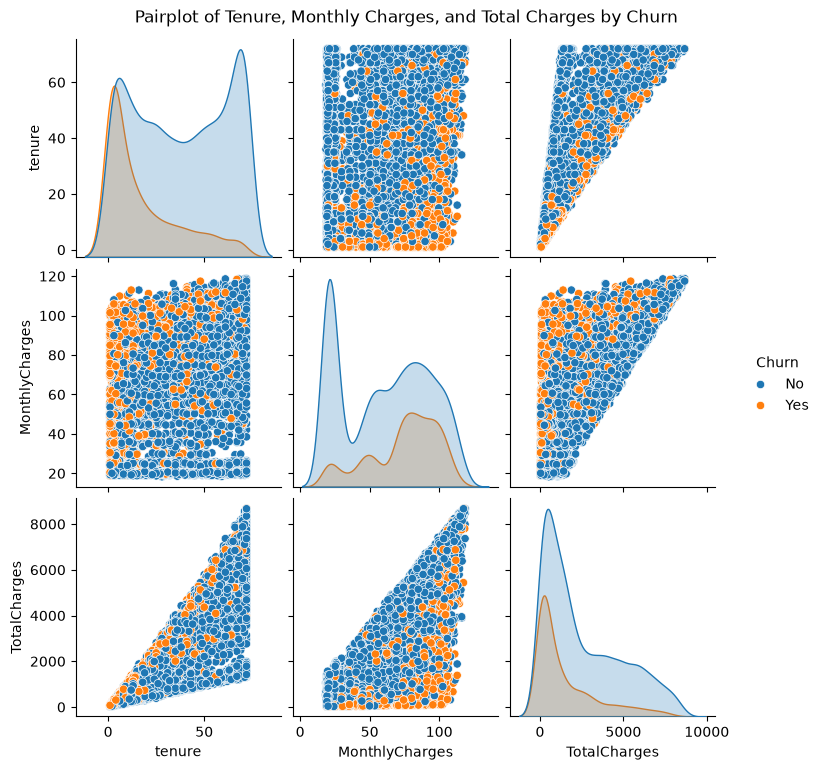

In [52]:
# okay so far we have seen the distribution of the target variable 'Churn' with respect to various categorical features. Now let's check the distribution of the target variable 'Churn' with respect to numerical features like 'tenure', 'MonthlyCharges', and 'TotalCharges'.

plot = sns.boxplot(x='Churn', y='tenure', data=df)
plot.set_title('Distribution of Churn by Tenure')
plot.set_xlabel('Churn')
plot.set_ylabel('Tenure')
plt.show()

plot = sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plot.set_title('Distribution of Churn by Monthly Charges')
plot.set_xlabel('Churn')
plot.set_ylabel('Monthly Charges')
plt.show()

plot = sns.boxplot(x='Churn', y='TotalCharges', data=df)
plot.set_title('Distribution of Churn by Total Charges')
plot.set_xlabel('Churn')
plot.set_ylabel('Total Charges')
plt.show()

plot = sns.pairplot(df, hue='Churn', vars=['tenure', 'MonthlyCharges', 'TotalCharges'])
plot.fig.suptitle('Pairplot of Tenure, Monthly Charges, and Total Charges by Churn', y=1.02)
plt.show()


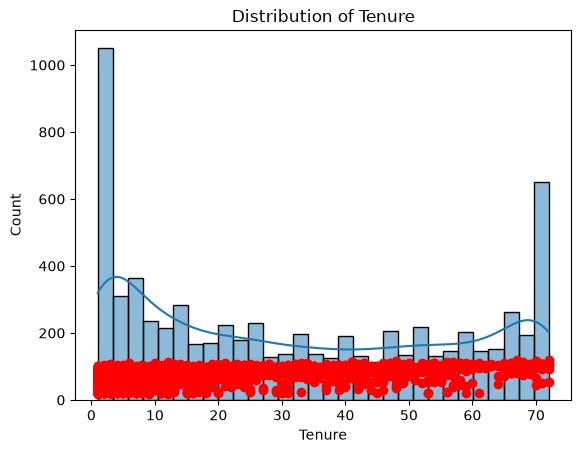

In [60]:
plt.plot(df['tenure'][df['Churn'] == 'Yes'], df['MonthlyCharges'][df['Churn'] == 'Yes'], 'ro', label='Churned')
plot = sns.histplot(df['tenure'], bins=30, kde=True)
plot.set_title('Distribution of Tenure')
plot.set_xlabel('Tenure')
plot.set_ylabel('Count')
plt.show()

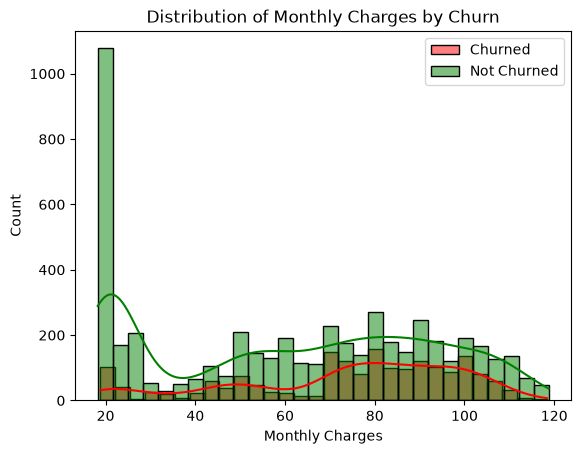

In [ ]:
# so know we know that people with lower tenure are more likely to churn. 
# Let's check the distribution of MonthlyCharges and TotalCharges with respect to Churn.

plot = sns.histplot(df['MonthlyCharges'][df['Churn'] == 'Yes'], bins=30, kde=True, color='red', label='Churned')
plot = sns.histplot(df['MonthlyCharges'][df['Churn'] == 'No'], bins=30, kde=True, color='green', label='Not Churned')
plot.set_title('Distribution of Monthly Charges by Churn')
plot.set_xlabel('Monthly Charges')
plot.set_ylabel('Count')
plt.legend()
plt.show()

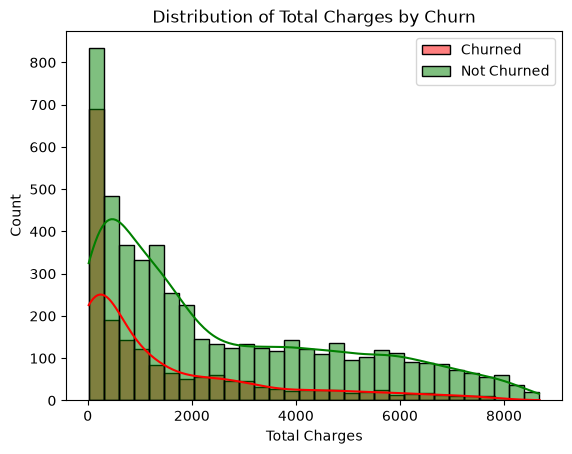

In [62]:
# this is interesting, we can see that people with higher monthly charges are more likely to churn.
# Let's check the distribution of TotalCharges with respect to Churn.

plot = sns.histplot(df['TotalCharges'][df['Churn'] == 'Yes'], bins=30, kde=True, color='red', label='Churned')
plot = sns.histplot(df['TotalCharges'][df['Churn'] == 'No'], bins=30, kde=True, color='green', label='Not Churned')
plot.set_title('Distribution of Total Charges by Churn')
plot.set_xlabel('Total Charges')
plot.set_ylabel('Count')
plt.legend()
plt.show()

In [72]:
# the higher the total charges, it doesn't look like it has a significant effect on churn.
#  However, we can see that people with lower total charges are more likely to churn, which may indicate that they are not satisfied with the service and are leaving early.
# so maybe we can say that people with lower tenure and higher monthly charges are more likely to churn.



# so to update significant features that may affect churn are:
# 1. tenure - lower tenure is more likely to churn
# 2. MonthlyCharges - higher monthly charges are more likely to churn
# 3. TotalCharges - lower total charges are more likely to churn (keep in mind that this is not a strong correlation, but it may be an indicator of dissatisfaction with the service
# 4. Contract - month-to-month contracts are more likely to churn
# 5. PaymentMethod - electronic check is more likely to churn (but this may be due to the fact that electronic check is more common among month-to-month contracts, which are more likely to churn)
# 6. InternetService - fiber optic is more likely to churn (but this may be due to the fact that fiber optic is more common among month-to-month contracts, which are more likely to churn
# 7. MultipleLines - customers with multiple lines are more likely to churn (but this may be due to the fact that customers with multiple lines are more likely to have fiber optic internet service, which is more likely to churn)
# 8. PhoneService - customers with phone service are more likely to churn (but this may be due to the fact that customers with phone service are more likely to have fiber optic internet service, which is more likely to churn)
# 9. Dependents - customers with dependents are more likely to churn (but this may be due to the fact that customers with dependents are more likely to have fiber optic internet service, which is more likely to churn)
#10. PaperlessBilling - customers with paperless billing are more likely to churn (but this may be due to the fact that paperless billing is more common )

# remaining safe for a simple model, we can say that the most significant features that may affect churn are:
# 1. tenure
# 2. MonthlyCharges
# 3. Contract
# 4. totalCharges - (specifically lower total charges, since this may indicate dissatisfaction with the service)

#i will expand on features after I build a simple model and see how it performs.
